# Data Slayer 4.0 Main Notebook

Objective: Mengklasifikasikan klip ujian berdurasi 1 detik (30 frame) menjadi normal (0) atau cheating (1) dengan menyusun ulang klip test menjadi video utuh lalu memprediksi per video dari fitur DINOv3 ViT-H+, menggunakan F1-Macro sebagai metrik evaluasi.

# Sinkronisasi versi modules dan libraries

In [1]:
import sys
print(sys.version)
%pip install -q torch==2.11.0 opencv-python==5.0.0.93 scikit-learn==1.8.0 scipy==1.17.1 numpy==2.4.4 pandas==2.3.3 matplotlib==3.10.9 tqdm==4.67.3

3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\leouw\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


# Import modules dan libraries

In [2]:
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.optimize import linear_sum_assignment
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm

SEED = 42
DATA = Path("../data")
CACHE = Path("../cache/dinov3_hplus_224x400_step3_bf16")
REBUILT = DATA / "test_rebuilt"
N_FOLDS = 5
FRAMES_PER_CLIP = 30
LINK_MAX = 3.0
N_TEST_SUBJECTS = 6
VIDEOS_PER_GROUP = 8
LAGS = [5, 15, 50]
CHEAT_FROM_SECONDS = [6, 7, 8]
MAX_SHIFT = 30
PAIR_WEIGHT = 3.0
CHEAT_ACTIONS = ["Looking_Under_the_Desk", "Reading_Hidden_Notes", "Repeated_Peeking", "Using_Smartwatch"]
NORMAL_ACTIONS = ["Checking_Smartwatch", "Looking_Around", "Thinking", "Writing_Answers"]
ACTIONS = CHEAT_ACTIONS + NORMAL_ACTIONS
IS_CHEAT = np.array([a in CHEAT_ACTIONS for a in ACTIONS])
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
np.random.seed(SEED)
print(torch.__version__, DEVICE)

2.11.0+cu128 cuda


# Import datasets

In [3]:
rows = []
for path in sorted(DATA.glob("train/*/*/*.MOV")):
    view, action = path.stem.split("_", 1)
    rows.append({
        "video": f"{path.parent.parent.name}/{path.parent.name}/{path.stem}",
        "path": str(path),
        "label": int(path.parent.parent.name == "cheat"),
        "subject": int(path.parent.name.split("_")[1]),
        "view": view,
        "action": action,
    })
train = pd.DataFrame(rows)
train["action_id"] = train["action"].map(ACTIONS.index)
sub = pd.read_csv(DATA / "sample_submission.csv")
print(train.shape, sub.shape)
train.head()

(416, 7) (1515, 2)


,video,path,label,subject,view,action,action_id
0,cheat/subject_1/front_Looking_Under_the_Desk,..\data\train\cheat\subject_1\front_Looking_Un...,1,1,front,Looking_Under_the_Desk,0
1,cheat/subject_1/front_Reading_Hidden_Notes,..\data\train\cheat\subject_1\front_Reading_Hi...,1,1,front,Reading_Hidden_Notes,1
2,cheat/subject_1/front_Repeated_Peeking,..\data\train\cheat\subject_1\front_Repeated_P...,1,1,front,Repeated_Peeking,2
3,cheat/subject_1/front_Using_Smartwatch,..\data\train\cheat\subject_1\front_Using_Smar...,1,1,front,Using_Smartwatch,3
4,cheat/subject_1/side_Looking_Under_the_Desk,..\data\train\cheat\subject_1\side_Looking_Und...,1,1,side,Looking_Under_the_Desk,0


# EDA

### Struktur train
Setiap subjek punya 16 video: 2 view x 8 aksi, dan setiap aksi muncul tepat satu kali per subjek per view. Struktur ini yang nanti dicari kembali di test.

In [4]:
print("subjek:", train["subject"].nunique(), "| video:", len(train))
train.groupby(["subject", "view"])["action"].nunique().value_counts().rename("jumlah grup subjek-view").rename_axis("aksi unik per grup").to_frame()

subjek: 26 | video: 416


,jumlah grup subjek-view
aksi unik per grup,
8,52


# Feature Extraction

### Fitur DINOv3 dari cache
Memakai fitur per frame DINOv3 ViT-H+ (CLS + rata-rata patch, 2560 dimensi, 10 fps) yang sudah diekstrak oleh baseline_cv.ipynb, sehingga backbone tidak perlu dijalankan lagi.

In [5]:
assert (CACHE / "test.npy").exists(), "cache fitur belum ada, jalankan baseline_cv.ipynb sampai bagian Feature Extraction"
train_feats = [np.load(CACHE / "train" / (v.replace("/", "__") + ".npy")).astype(np.float32) for v in train["video"]]
clip_feats = np.load(CACHE / "test.npy").astype(np.float32)
print("video train:", len(train_feats), "| satu video:", train_feats[0].shape, "| klip test:", clip_feats.shape)

video train: 416 | satu video: (136, 2560) | klip test: (1515, 10, 2560)


# Aggregate
Menyusun ulang 1.515 klip test menjadi video utuh dengan struktur yang sama seperti train (subjek, view, video), agar prediksi bisa dibuat per video dan bukan per klip 1 detik.

### Penyambungan klip
Frame terakhir sebuah klip hampir sama dengan frame pertama klip lanjutannya. Dua klip disambung jika keduanya saling menjadi pasangan terdekat dan selisih pikselnya di bawah LINK_MAX.

In [6]:
def load_small(args):
    seq, k = args
    img = cv2.imread(str(DATA / "test" / seq / f"{k:02d}.jpg"), cv2.IMREAD_GRAYSCALE)
    return cv2.resize(img, (160, 90), interpolation=cv2.INTER_AREA).astype(np.float32).ravel()


with ThreadPoolExecutor(16) as ex:
    first = torch.tensor(np.stack(list(ex.map(load_small, [(s, 1) for s in sub["id"]])))).to(DEVICE)
    last = torch.tensor(np.stack(list(ex.map(load_small, [(s, FRAMES_PER_CLIP) for s in sub["id"]])))).to(DEVICE)
dist = torch.cdist(last, first, p=1) / first.shape[1]
dist.fill_diagonal_(float("inf"))
succ = dist.argmin(1).cpu().numpy()
pred = dist.argmin(0).cpu().numpy()
succ_dist = dist.min(1).values.cpu().numpy()
n_clips = len(sub)
linked = (pred[succ] == np.arange(n_clips)) & (succ_dist < LINK_MAX)
next_clip = {i: succ[i] for i in range(n_clips) if linked[i]}
has_prev = set(next_clip.values())
chains = []
for i in range(n_clips):
    if i not in has_prev:
        chain = [i]
        while chain[-1] in next_clip:
            chain.append(next_clip[chain[-1]])
        chains.append(chain)
assert sum(len(c) for c in chains) == n_clips
print("sambungan:", int(linked.sum()), "| video test:", len(chains))
pd.Series([len(c) for c in chains]).value_counts().sort_index().rename("jumlah video").rename_axis("panjang (detik)").to_frame().T

sambungan: 1419 | video test: 96


panjang (detik),14,15,16,17,18,19
jumlah video,2,37,40,15,1,1


### Selisih piksel sambungan
Selisih ke pasangan terdekat (sambungan asli) umumnya lebih kecil daripada ke pasangan terdekat kedua, tetapi keduanya masih tumpang tindih. Karena itu syarat utamanya adalah saling menjadi pasangan terdekat, dan LINK_MAX hanya mencegah ujung video tersambung ke video lain.

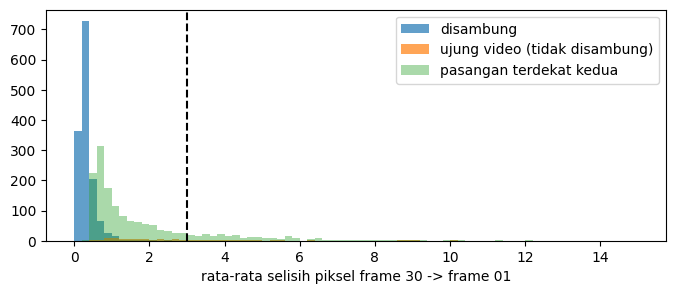

In [7]:
second = dist.sort(1).values[:, 1].cpu().numpy()
plt.figure(figsize=(8, 3))
bins = np.linspace(0, 15, 76)
plt.hist(succ_dist[linked], bins=bins, alpha=0.7, label="disambung")
plt.hist(succ_dist[~linked], bins=bins, alpha=0.7, label="ujung video (tidak disambung)")
plt.hist(second, bins=bins, alpha=0.4, label="pasangan terdekat kedua")
plt.axvline(LINK_MAX, color="k", ls="--")
plt.xlabel("rata-rata selisih piksel frame 30 -> frame 01")
plt.legend()
plt.show()

### View dan subjek
Menentukan struktur setiap video test:
- view: mengikuti view video train yang paling mirip.
- subjek per view: clustering Ward menjadi 6 kelompok, setiap kelompok harus berisi tepat 8 video.
- pasangan front-side: kedua kamera merekam take yang sama, jadi naik-turun gerakannya terjadi pada waktu yang sama. Kelompok front dan side dari orang yang sama dicocokkan dari kemiripan waktu gerakan itu (korelasi silang profil gerakan).

In [8]:
def normalize(x):
    return x / np.linalg.norm(x, axis=-1, keepdims=True)


def motion_profile(feats, k=5):
    energy = np.linalg.norm(feats[k:] - feats[:-k], axis=1)
    return (energy - energy.mean()) / (energy.std() + 1e-9)


def timing_match(a, b):
    best = -1.0
    for shift in range(-MAX_SHIFT, MAX_SHIFT + 1):
        x, y = (a[shift:], b) if shift >= 0 else (a, b[-shift:])
        n = min(len(x), len(y))
        if n > 60:
            best = max(best, float(np.dot(x[:n], y[:n]) / n))
    return best


def timing_matrix(profiles, front_idx, side_idx):
    return np.array([[timing_match(profiles[i], profiles[j]) for j in side_idx] for i in front_idx])


test_feats = [clip_feats[c].reshape(-1, clip_feats.shape[-1]) for c in chains]
train_mean = np.stack([f.mean(0) for f in train_feats])
test_mean = np.stack([f.mean(0) for f in test_feats])
center = train_mean.mean(0)
nearest = (normalize(test_mean - center) @ normalize(train_mean - center).T).argmax(1)
test_videos = pd.DataFrame({"n_clips": [len(c) for c in chains], "view": train["view"].values[nearest]})

test_videos["cluster"] = -1
for view in ["front", "side"]:
    idx = np.where(test_videos["view"] == view)[0]
    x = normalize(test_mean[idx] - test_mean[idx].mean(0))
    test_videos.loc[idx, "cluster"] = fcluster(linkage(x, "ward"), N_TEST_SUBJECTS, "maxclust")
assert (test_videos.groupby(["view", "cluster"]).size() == VIDEOS_PER_GROUP).all(), "kelompok subjek tidak berisi 8 video"

test_profiles = [motion_profile(f) for f in test_feats]
group_idx = {(v, k): np.where((test_videos["view"] == v) & (test_videos["cluster"] == k))[0]
             for v in ["front", "side"] for k in range(1, N_TEST_SUBJECTS + 1)}
sim = np.zeros((N_TEST_SUBJECTS, N_TEST_SUBJECTS))
for f in range(N_TEST_SUBJECTS):
    for s in range(N_TEST_SUBJECTS):
        m = timing_matrix(test_profiles, group_idx[("front", f + 1)], group_idx[("side", s + 1)])
        sim[f, s] = m[linear_sum_assignment(-m)].mean()
front_k, side_k = linear_sum_assignment(-sim)
subject_of = {("front", f + 1): i + 1 for i, f in enumerate(front_k)} | {("side", s + 1): i + 1 for i, s in enumerate(side_k)}
test_videos["subject"] = [subject_of[(v, k)] for v, k in zip(test_videos["view"], test_videos["cluster"])]
test_videos["video_no"] = test_videos.groupby(["subject", "view"]).cumcount() + 1
test_videos["video"] = [f"subject_T{s}/{v}_video_{n:02d}" for s, v, n in zip(test_videos["subject"], test_videos["view"], test_videos["video_no"])]
print("kemiripan waktu gerakan pasangan terpilih:", sim[front_k, side_k].round(2), "| pasangan lain terbaik:", np.sort(sim, axis=1)[:, -2].max().round(2))
test_videos.groupby(["subject", "view"]).agg(video=("video", "count"), detik=("n_clips", "sum")).unstack()

kemiripan waktu gerakan pasangan terpilih: [0.63 0.59 0.44 0.61 0.67 0.69] | pasangan lain terbaik: 0.57


video      detik     
view    front side front side
subject                      
1           8    8   121  124
2           8    8   128  131
3           8    8   122  134
4           8    8   122  126
5           8    8   125  130
6           8    8   124  128

### Test dengan struktur train
Menyimpan hasil susunan ke data/test_rebuilt:
- mapping.csv: asal setiap klip (video, subjek, view, urutan dalam video).
- subject_T*/{view}_video_*.mp4: video utuh hasil sambungan klip, sama seperti susunan folder train tetapi tanpa nama aksi.

In [9]:
mapping = pd.DataFrame([
    {"id": sub["id"][c], "vid": vid, "video": row.video, "subject": row.subject, "view": row.view, "position": pos}
    for vid, (chain, row) in enumerate(zip(chains, test_videos.itertuples())) for pos, c in enumerate(chain)
]).sort_values("id").reset_index(drop=True)
assert (mapping["id"] == sub["id"]).all()
REBUILT.mkdir(exist_ok=True)
mapping.to_csv(REBUILT / "mapping.csv", index=False)
for vid, row in tqdm(list(enumerate(test_videos.itertuples()))):
    out_path = REBUILT / (row.video + ".mp4")
    if out_path.exists():
        continue
    out_path.parent.mkdir(exist_ok=True)
    writer = cv2.VideoWriter(str(out_path), cv2.VideoWriter_fourcc(*"mp4v"), 30, (640, 360))
    for c in chains[vid]:
        for k in range(1, FRAMES_PER_CLIP + 1):
            writer.write(cv2.imread(str(DATA / "test" / sub["id"][c] / f"{k:02d}.jpg")))
    writer.release()
print("video tersimpan:", len(list(REBUILT.glob("*/*.mp4"))))
mapping.head()

  0%|          | 0/96 [00:00<?, ?it/s]

video tersimpan: 96


,id,vid,video,subject,view,position
0,test_seq_00001,46,subject_T6/side_video_05,6,side,6
1,test_seq_00002,83,subject_T6/front_video_08,6,front,11
2,test_seq_00003,0,subject_T3/side_video_01,3,side,1
3,test_seq_00004,61,subject_T5/front_video_04,5,front,8
4,test_seq_00005,10,subject_T2/front_video_03,2,front,7


### Contoh video hasil sambungan
Satu frame per detik dari satu video test, untuk memeriksa secara visual bahwa urutan klipnya menyambung.

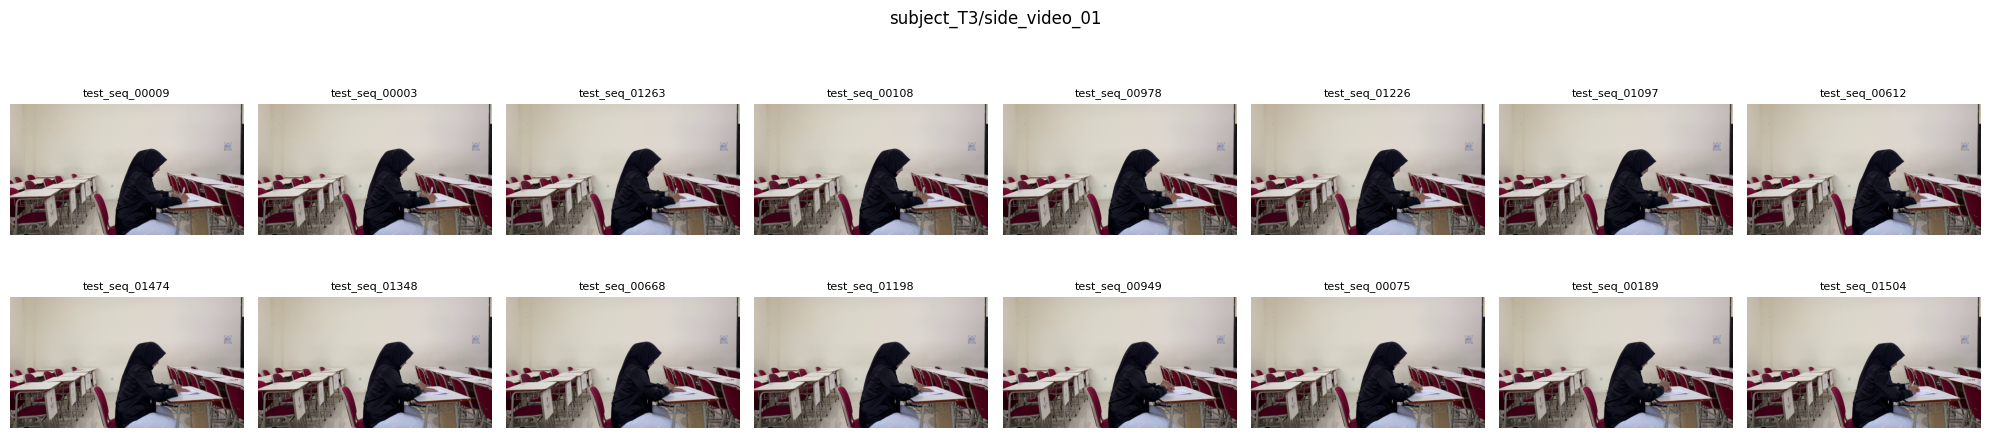

In [10]:
chain = chains[0]
fig, axes = plt.subplots(2, 8, figsize=(20, 5))
for ax in axes.ravel():
    ax.axis("off")
for ax, c in zip(axes.ravel(), chain):
    ax.imshow(cv2.cvtColor(cv2.imread(str(DATA / "test" / sub["id"][c] / "01.jpg")), cv2.COLOR_BGR2RGB))
    ax.set_title(sub["id"][c], fontsize=8)
plt.suptitle(test_videos["video"][0])
plt.tight_layout()
plt.show()

### Awal aksi di dalam video
Jarak fitur setiap detik terhadap 3 detik pertama videonya (1 = sama seperti awal). Di train maupun test, subjek menulis biasa sampai sekitar detik ke-7 dan aksi baru mulai di detik ke-7 sampai ke-8, kecuali Writing_Answers yang tetap datar.

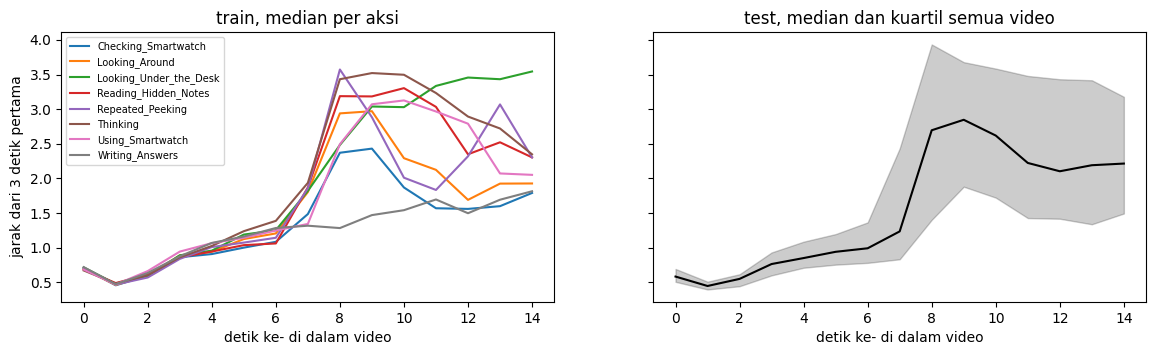

In [11]:
def start_distance(feats, n_seconds=15):
    seconds = feats[:len(feats) // 10 * 10].reshape(-1, 10, feats.shape[1]).mean(1)
    base = feats[:30].mean(0)
    spread = np.linalg.norm(feats[:30] - base, axis=1).mean()
    dist = np.linalg.norm(seconds - base, axis=1) / spread
    return np.pad(dist, (0, max(0, n_seconds - len(dist))), constant_values=np.nan)[:n_seconds]


train_dist = pd.DataFrame([start_distance(f) for f in train_feats])
test_dist = pd.DataFrame([start_distance(f) for f in test_feats])
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5), sharey=True)
for action, rows in train_dist.groupby(train["action"].values):
    axes[0].plot(rows.median(), label=action)
axes[0].set_title("train, median per aksi")
axes[0].legend(fontsize=7)
axes[1].plot(test_dist.median(), color="k")
axes[1].fill_between(range(15), test_dist.quantile(0.25), test_dist.quantile(0.75), alpha=0.2, color="k")
axes[1].set_title("test, median dan kuartil semua video")
for ax in axes:
    ax.set_xlabel("detik ke- di dalam video")
axes[0].set_ylabel("jarak dari 3 detik pertama")
plt.show()

# Preprocessing

### Fitur per video
Merangkum semua frame satu video (10 fps) menjadi satu vektor:
- mean: rata-rata fitur, yaitu apa yang terlihat.
- std: standar deviasi antar waktu, yaitu seberapa banyak hal itu berubah.
- lag 5, 15, 50: standar deviasi selisih fitur pada jarak 0,5, 1,5 dan 5 detik, untuk membedakan gerakan cepat dari gerakan lambat.

In [12]:
def video_vector(feats):
    return np.concatenate([feats.mean(0), feats.std(0)] + [(feats[k:] - feats[:-k]).std(0) for k in LAGS])


X_train = np.stack([video_vector(f) for f in train_feats])
X_test = np.stack([video_vector(f) for f in test_feats])
y_action = train["action_id"].values
y_label = train["label"].values
print(X_train.shape, X_test.shape)

(416, 12800) (96, 12800)


### Pembagian fold per subjek
Semua video dari satu subjek berada di fold yang sama, sehingga skor validasi mengukur kemampuan model pada orang yang belum pernah dilihat.

In [13]:
train["fold"] = -1
splitter = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
for fold, (_, val_idx) in enumerate(splitter.split(train, train["action_id"], train["subject"])):
    train.loc[val_idx, "fold"] = fold
train.groupby("fold").agg(subjek=("subject", "nunique"), video=("video", "count"), cheat=("label", "mean"))

,subjek,video,cheat
fold,,,
0,6,96,0.5
1,5,80,0.5
2,5,80,0.5
3,5,80,0.5
4,5,80,0.5


# Classifier Models

### Logistic Regression per video
Memprediksi 8 aksi dari vektor video. Peluang cheating adalah jumlah peluang 4 aksi cheating.

In [14]:
def make_model():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.3, max_iter=500))


oof = np.zeros((len(train), len(ACTIONS)))
for fold in range(N_FOLDS):
    tr, va = (train["fold"] != fold).values, (train["fold"] == fold).values
    oof[va] = make_model().fit(X_train[tr], y_action[tr]).predict_proba(X_train[va])
test_proba = make_model().fit(X_train, y_action).predict_proba(X_test)
oof_plain = oof.argmax(1)
print(f"F1-Macro OOF: {f1_score(y_label, IS_CHEAT[oof_plain], average='macro'):.4f} | akurasi 8 aksi: {(oof_plain == y_action).mean():.4f}")

F1-Macro OOF: 0.8628 | akurasi 8 aksi: 0.7764


### Penugasan satu aksi per video
Dalam satu grup subjek-view setiap aksi muncul tepat satu kali, jadi 8 video dipasangkan ke 8 aksi sekaligus dengan Hungarian (memaksimalkan total log peluang). Hasilnya selalu 4 cheating dan 4 normal per grup.

In [15]:
def assign_actions(proba, groups):
    out = np.zeros(len(proba), dtype=int)
    for g in np.unique(groups):
        idx = np.where(groups == g)[0]
        rows, cols = linear_sum_assignment(-np.log(proba[idx] + 1e-9))
        out[idx[rows]] = cols
    return out


train_group = (train["subject"].astype(str) + "_" + train["view"]).values
test_group = (test_videos["subject"].astype(str) + "_" + test_videos["view"]).values
oof_assigned = assign_actions(oof, train_group)
test_per_group = assign_actions(test_proba, test_group)
print(f"F1-Macro OOF: {f1_score(y_label, IS_CHEAT[oof_assigned], average='macro'):.4f} | akurasi 8 aksi: {(oof_assigned == y_action).mean():.4f}")

F1-Macro OOF: 0.9519 | akurasi 8 aksi: 0.9327


### Penugasan gabungan front dan side
Video front dan side dari take yang sama harus mendapat aksi yang sama. Penugasan aksi di kedua view dicari bersama: total log peluang ditambah PAIR_WEIGHT kali kemiripan waktu gerakan antara video front dan side yang mendapat aksi yang sama, dioptimalkan bergantian dengan Hungarian.

In [16]:
def joint_assign(score_front, score_side, timing):
    n = len(ACTIONS)

    def hungarian(cost):
        out = np.zeros(n, dtype=int)
        rows, cols = linear_sum_assignment(-cost)
        out[rows] = cols
        return out

    def objective(pf, ps):
        f_of, s_of = np.argsort(pf), np.argsort(ps)
        return score_front[np.arange(n), pf].sum() + score_side[np.arange(n), ps].sum() + PAIR_WEIGHT * timing[f_of, s_of].sum()

    rows, cols = linear_sum_assignment(-timing)
    paired = hungarian(score_front[rows] + score_side[cols])
    start_paired = (np.zeros(n, dtype=int), np.zeros(n, dtype=int))
    start_paired[0][rows], start_paired[1][cols] = paired, paired
    best = None
    for pf, ps in [(hungarian(score_front), hungarian(score_side)), start_paired]:
        for _ in range(10):
            ps = hungarian(score_side + PAIR_WEIGHT * timing[np.argsort(pf)].T)
            pf = hungarian(score_front + PAIR_WEIGHT * timing[:, np.argsort(ps)])
        value = objective(pf, ps)
        if best is None or value > best[0]:
            best = (value, pf, ps)
    return best[1], best[2]


def assign_joint(log_proba, profiles, subjects, views):
    out = np.zeros(len(log_proba), dtype=int)
    for s in np.unique(subjects):
        f = np.where((subjects == s) & (views == "front"))[0]
        d = np.where((subjects == s) & (views == "side"))[0]
        out[f], out[d] = joint_assign(log_proba[f], log_proba[d], timing_matrix(profiles, f, d))
    return out


train_profiles = [motion_profile(f) for f in train_feats]
oof_joint = assign_joint(np.log(oof + 1e-9), train_profiles, train["subject"].values, train["view"].values)
test_assigned = assign_joint(np.log(test_proba + 1e-9), test_profiles, test_videos["subject"].values, test_videos["view"].values)
scores = pd.DataFrame({
    "F1-Macro": [f1_score(y_label, IS_CHEAT[p], average="macro") for p in (oof_plain, oof_assigned, oof_joint)],
    "akurasi 8 aksi": [(p == y_action).mean() for p in (oof_plain, oof_assigned, oof_joint)],
}, index=["argmax", "Hungarian per grup", "gabungan front + side"]).round(4)
scores

,F1-Macro,akurasi 8 aksi
argmax,0.8628,0.7764
Hungarian per grup,0.9519,0.9327
gabungan front + side,0.9615,0.9615


### Akurasi per aksi dan view

In [17]:
train.assign(benar=IS_CHEAT[oof_joint] == y_label).pivot_table(index=["label", "action"], columns="view", values="benar").round(3)

view                          front   side
label action                              
0     Checking_Smartwatch     0.885  0.923
      Looking_Around          0.962  0.962
      Thinking                1.000  1.000
      Writing_Answers         1.000  0.962
1     Looking_Under_the_Desk  1.000  1.000
      Reading_Hidden_Notes    1.000  0.923
      Repeated_Peeking        0.962  0.962
      Using_Smartwatch        0.885  0.962

# Submission

In [ ]:
Path("submissions").mkdir(exist_ok=True)
Path("preds").mkdir(exist_ok=True)
np.save("preds/main_oof.npy", oof)
np.save("preds/main_test.npy", test_proba)
test_videos["action_pred"] = [ACTIONS[a] for a in test_assigned]
test_videos["label"] = IS_CHEAT[test_assigned].astype(int)
test_videos["action_per_group"] = [ACTIONS[a] for a in test_per_group]
test_videos.to_csv(REBUILT / "videos_pred.csv", index=False)
print("video test yang labelnya berubah karena gabungan front + side:", int((IS_CHEAT[test_assigned] != IS_CHEAT[test_per_group]).sum()), "dari", len(test_videos))
submission = pd.DataFrame({"id": sub["id"], "label": test_videos["label"].values[mapping["vid"]]})
submission.to_csv("submissions/submission.csv", index=False)
print(submission["label"].value_counts(normalize=True).round(3).to_dict())
submission.head()

video test yang labelnya berubah karena gabungan front + side: 4 dari 96
{1: 0.505, 0: 0.495}


,id,label
0,test_seq_00001,0
1,test_seq_00002,0
2,test_seq_00003,0
3,test_seq_00004,0
4,test_seq_00005,0


### Label per detik
Bagian awal video cheating berisi subjek yang menulis biasa, dan skor LB yang sudah diketahui paling cocok jika hanya klip dari sekitar detik ke-7 yang berlabel cheating. Batas pastinya belum diketahui, jadi dibuat satu file untuk setiap kandidat batas.

In [19]:
shares = {}
for k in CHEAT_FROM_SECONDS:
    late = submission.copy()
    late["label"] = ((submission["label"] == 1) & (mapping["position"] >= k)).astype(int)
    late.to_csv(f"submissions/main_from{k}.csv", index=False)
    shares[f"main_from{k}.csv"] = late["label"].mean()
pd.Series(shares, name="porsi klip cheating").round(3).to_frame()

,porsi klip cheating
main_from6.csv,0.315
main_from7.csv,0.283
main_from8.csv,0.251
